In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../DATA/seismic-bumps.csv")

In [3]:
df.head()

,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,hazard,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89,energy,maxenergy,class
0,a,a,N,15180,48,-72,-72,a,0,0,0,0,0,0,0,0,0,0,0
1,a,a,N,14720,33,-70,-79,a,1,0,1,0,0,0,0,0,2000,2000,0
2,a,a,N,8050,30,-81,-78,a,0,0,0,0,0,0,0,0,0,0,0
3,a,a,N,28820,171,-23,40,a,1,0,1,0,0,0,0,0,3000,3000,0
4,a,a,N,12640,57,-63,-52,a,0,0,0,0,0,0,0,0,0,0,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2584 entries, 0 to 2583
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   seismic         2584 non-null   object
 1   seismoacoustic  2584 non-null   object
 2   shift           2584 non-null   object
 3   genergy         2584 non-null   int64 
 4   gpuls           2584 non-null   int64 
 5   gdenergy        2584 non-null   int64 
 6   gdpuls          2584 non-null   int64 
 7   hazard          2584 non-null   object
 8   nbumps          2584 non-null   int64 
 9   nbumps2         2584 non-null   int64 
 10  nbumps3         2584 non-null   int64 
 11  nbumps4         2584 non-null   int64 
 12  nbumps5         2584 non-null   int64 
 13  nbumps6         2584 non-null   int64 
 14  nbumps7         2584 non-null   int64 
 15  nbumps89        2584 non-null   int64 
 16  energy          2584 non-null   int64 
 17  maxenergy       2584 non-null   int64 
 18  class   

In [5]:
df['class'].value_counts()

class
0    2414
1     170
Name: count, dtype: int64

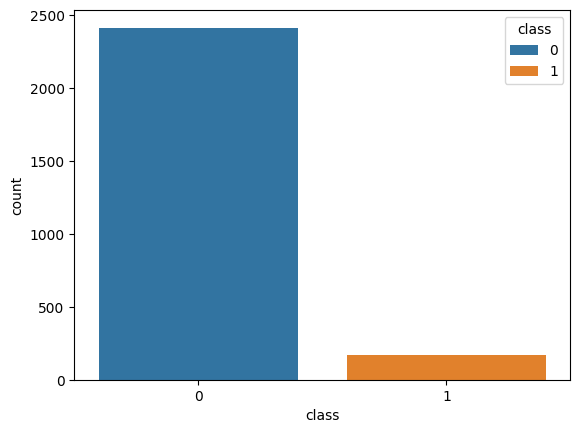

In [7]:
sns.countplot(data=df, x='class', hue='class');

In [10]:
df = df.drop(['nbumps6', 'nbumps7', 'nbumps89'], axis=1)

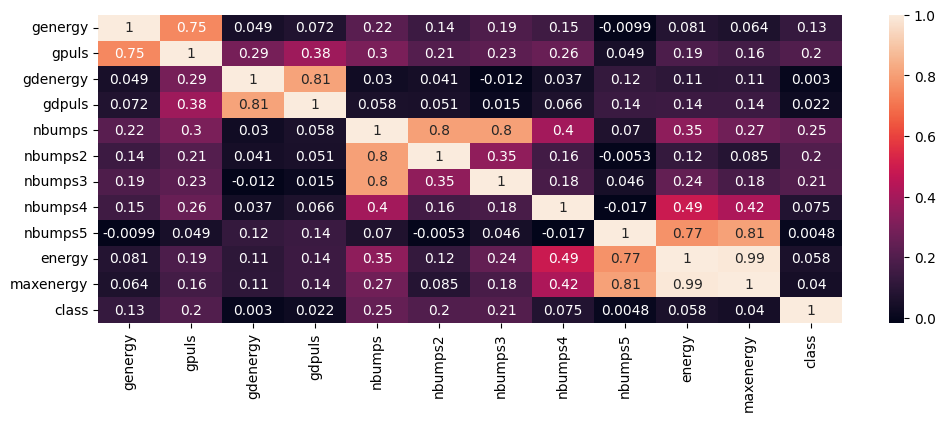

In [12]:
plt.figure(figsize=(12, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True);

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest

In [14]:
X = df.drop('class', axis=1)

In [15]:
y = df['class']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104)

In [19]:
num_features = X_train.select_dtypes(exclude='object').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

In [20]:
iso_forest = IsolationForest(contamination=0.01, n_estimators=100, n_jobs=-1, random_state=104)

In [21]:
mask = iso_forest.fit_predict(X_train[num_features])

In [22]:
X_train_cleaned = X_train[mask==1]
y_train_cleaned = y_train[mask==1]

In [23]:
X_train.shape

(2067, 15)

In [24]:
X_train_cleaned.shape

(2046, 15)

In [26]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler_2', StandardScaler())
])

In [27]:
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ],
    remainder='passthrough'
)

In [55]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegressionCV(Cs=5, cv=3, penalty='l2', solver='lbfgs',
                                   max_iter=100, n_jobs=-1, class_weight='balanced', random_state=104))
])

In [56]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [57]:
%%time
pipe.fit(X_train_cleaned, y_train_cleaned)

CPU times: total: 46.9 ms
Wall time: 3.34 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [58]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [59]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [0.0001]


In [60]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [61]:
accuracy

0.8336557059961315

In [62]:
recall

0.6363636363636364

In [63]:
precision

0.22105263157894736

In [64]:
roc_auc_train

0.778627888506486

In [65]:
roc_auc_test

0.8047207613323316

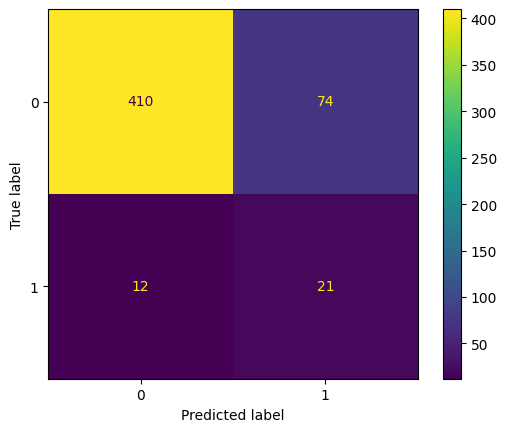

In [66]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test)

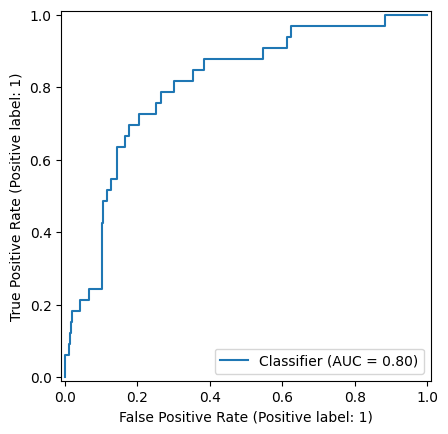

In [67]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba);

In [68]:
%%time
pipe.fit(X, y)

CPU times: total: 31.2 ms
Wall time: 3.36 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [69]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")

Лучшее значение C: [0.0001]


In [70]:
y_full_proba = pipe.predict_proba(X)[:, 1]

In [71]:
roc_auc_full = roc_auc_score(y, y_full_proba)

In [72]:
roc_auc_full

0.7840148155368196

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2584 entries, 0 to 2583
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   seismic         2584 non-null   object
 1   seismoacoustic  2584 non-null   object
 2   shift           2584 non-null   object
 3   genergy         2584 non-null   int64 
 4   gpuls           2584 non-null   int64 
 5   gdenergy        2584 non-null   int64 
 6   gdpuls          2584 non-null   int64 
 7   hazard          2584 non-null   object
 8   nbumps          2584 non-null   int64 
 9   nbumps2         2584 non-null   int64 
 10  nbumps3         2584 non-null   int64 
 11  nbumps4         2584 non-null   int64 
 12  nbumps5         2584 non-null   int64 
 13  energy          2584 non-null   int64 
 14  maxenergy       2584 non-null   int64 
 15  class           2584 non-null   int64 
dtypes: int64(12), object(4)
memory usage: 323.1+ KB


In [74]:
custom_seismic_df = pd.DataFrame([
    {
        'seismic': 'a', 'seismoacoustic': 'a', 'shift': 'w',
        'genergy': 1000, 'gpuls': 10, 'gdenergy': -50, 'gdpuls': -5,
        'hazard': 'a', 'energy': 0, 'maxenergy': 0,
        'nbumps': 0, 'nbumps2': 0, 'nbumps3': 0, 'nbumps4': 0, 'nbumps5': 0, 'nbumps6': 0, 'nbumps7': 0, 'nbumps89': 0
    },
    {
        'seismic': 'c', 'seismoacoustic': 'c', 'shift': 'n',
        'genergy': 85000, 'gpuls': 1200, 'gdenergy': 400, 'gdpuls': 150,
        'hazard': 'c', 'energy': 15000, 'maxenergy': 8000,
        'nbumps': 5, 'nbumps2': 2, 'nbumps3': 2, 'nbumps4': 1, 'nbumps5': 0, 'nbumps6': 0, 'nbumps7': 0, 'nbumps89': 0
    }
])

In [75]:
custom_seismic_df

,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,hazard,energy,maxenergy,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89
0,a,a,w,1000,10,-50,-5,a,0,0,0,0,0,0,0,0,0,0
1,c,c,n,85000,1200,400,150,c,15000,8000,5,2,2,1,0,0,0,0


In [76]:
custom_seismic_df = custom_seismic_df[X_train_cleaned.columns]

In [77]:
preds = pipe.predict(custom_seismic_df)
preds_proba = pipe.predict_proba(custom_seismic_df)

In [78]:
classes_map = {
    0: "БЕЗОПАСНО (Сейсмическая угроза отсутствует) 🟢",
    1: "ОПАСНОСТЬ (Высокий риск горного удара / обвала!) 🚨"
}

expected_list = [
    "ШТАТНЫЙ РЕЖИМ РАБОТЫ ШАХТЫ (СЕЙСМОАКУСТИКА В НОРМЕ)",
    "КРИТИЧЕСКАЯ АКТИВНОСТЬ: АНОМАЛЬНЫЙ ВСПЛЕСК ЭНЕРГИИ И ПОДЗЕМНЫХ ТОЛЧКОВ"
]


print("=" * 90)
print("⛏️   ДЕПЛОЙ СИСТЕМЫ РАННЕГО ПРЕДУПРЕЖДЕНИЯ СЕЙСМИЧЕСКИХ УГРОЗ НА УГОЛЬНЫХ ШАХТАХ")
print("=" * 90)

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"\n📊 МОНИТОРИНГ РАБОЧЕЙ СМЕНЫ №{idx + 1}:")
    print(f" -> Профиль активности: {expected_list[idx]}")
    print(f" -> Вердикт ИИ-модели:   {classes_map[class_out]}")
    print(f" -> Уверенность логита:  {prob:.2f}%  📈")
    print("-" * 90)

⛏️   ДЕПЛОЙ СИСТЕМЫ РАННЕГО ПРЕДУПРЕЖДЕНИЯ СЕЙСМИЧЕСКИХ УГРОЗ НА УГОЛЬНЫХ ШАХТАХ

📊 МОНИТОРИНГ РАБОЧЕЙ СМЕНЫ №1:
 -> Профиль активности: ШТАТНЫЙ РЕЖИМ РАБОТЫ ШАХТЫ (СЕЙСМОАКУСТИКА В НОРМЕ)
 -> Вердикт ИИ-модели:   БЕЗОПАСНО (Сейсмическая угроза отсутствует) 🟢
 -> Уверенность логита:  56.42%  📈
------------------------------------------------------------------------------------------

📊 МОНИТОРИНГ РАБОЧЕЙ СМЕНЫ №2:
 -> Профиль активности: КРИТИЧЕСКАЯ АКТИВНОСТЬ: АНОМАЛЬНЫЙ ВСПЛЕСК ЭНЕРГИИ И ПОДЗЕМНЫХ ТОЛЧКОВ
 -> Вердикт ИИ-модели:   ОПАСНОСТЬ (Высокий риск горного удара / обвала!) 🚨
 -> Уверенность логита:  52.00%  📈
------------------------------------------------------------------------------------------


In [79]:
class_percents = df['class'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 93.4%, 1: 6.6%


In [80]:
import json
import os

advanced_report = {
    "project": "Seismic Bumps Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-08',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [81]:
from joblib import dump, load
import os

In [82]:
os.makedirs('model', exist_ok=True)

In [83]:
dump(pipe, "model/seismic_bumps_predict_logistic_regression_cv_2026_v1.pkl")

['model/seismic_bumps_predict_logistic_regression_cv_2026_v1.pkl']

In [84]:
loaded_pipe = load("model/seismic_bumps_predict_logistic_regression_cv_2026_v1.pkl")

In [85]:
preds = pipe.predict(custom_seismic_df)
preds_proba = pipe.predict_proba(custom_seismic_df)

In [86]:
classes_map = {
    0: "БЕЗОПАСНО (Сейсмическая угроза отсутствует) 🟢",
    1: "ОПАСНОСТЬ (Высокий риск горного удара / обвала!) 🚨"
}

expected_list = [
    "ШТАТНЫЙ РЕЖИМ РАБОТЫ ШАХТЫ (СЕЙСМОАКУСТИКА В НОРМЕ)",
    "КРИТИЧЕСКАЯ АКТИВНОСТЬ: АНОМАЛЬНЫЙ ВСПЛЕСК ЭНЕРГИИ И ПОДЗЕМНЫХ ТОЛЧКОВ"
]


print("=" * 90)
print("⛏️   ДЕПЛОЙ СИСТЕМЫ РАННЕГО ПРЕДУПРЕЖДЕНИЯ СЕЙСМИЧЕСКИХ УГРОЗ НА УГОЛЬНЫХ ШАХТАХ")
print("=" * 90)

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"\n📊 МОНИТОРИНГ РАБОЧЕЙ СМЕНЫ №{idx + 1}:")
    print(f" -> Профиль активности: {expected_list[idx]}")
    print(f" -> Вердикт ИИ-модели:   {classes_map[class_out]}")
    print(f" -> Уверенность логита:  {prob:.2f}%  📈")
    print("-" * 90)

⛏️   ДЕПЛОЙ СИСТЕМЫ РАННЕГО ПРЕДУПРЕЖДЕНИЯ СЕЙСМИЧЕСКИХ УГРОЗ НА УГОЛЬНЫХ ШАХТАХ

📊 МОНИТОРИНГ РАБОЧЕЙ СМЕНЫ №1:
 -> Профиль активности: ШТАТНЫЙ РЕЖИМ РАБОТЫ ШАХТЫ (СЕЙСМОАКУСТИКА В НОРМЕ)
 -> Вердикт ИИ-модели:   БЕЗОПАСНО (Сейсмическая угроза отсутствует) 🟢
 -> Уверенность логита:  56.42%  📈
------------------------------------------------------------------------------------------

📊 МОНИТОРИНГ РАБОЧЕЙ СМЕНЫ №2:
 -> Профиль активности: КРИТИЧЕСКАЯ АКТИВНОСТЬ: АНОМАЛЬНЫЙ ВСПЛЕСК ЭНЕРГИИ И ПОДЗЕМНЫХ ТОЛЧКОВ
 -> Вердикт ИИ-модели:   ОПАСНОСТЬ (Высокий риск горного удара / обвала!) 🚨
 -> Уверенность логита:  52.00%  📈
------------------------------------------------------------------------------------------
